In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats


In [2]:

# Mengambil dataset dari GitHub
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)

# Menampilkan 5 data pertama
df.head()


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:

# Mengambil 100 sampel secara acak
data = df['total_bill'].sample(
    n=100,
    random_state=42
).reset_index(drop=True)

# Menampilkan seluruh 100 sampel
print(data)

# Memastikan jumlah sampel
print("Jumlah sampel:", len(data))


0     19.82
1      8.77
2     24.55
3     25.89
4     13.00
      ...  
95    10.29
96    40.17
97    17.47
98    16.58
99    17.92
Name: total_bill, Length: 100, dtype: float64
Jumlah sampel: 100


In [4]:

print("Jumlah data:", len(data))
print("Rata-rata:", data.mean())
print("Nilai minimum:", data.min())
print("Nilai maksimum:", data.max())
print("Standar deviasi:", data.std())
print("Varians:", data.var())


Jumlah data: 100
Rata-rata: 19.272100000000002
Nilai minimum: 3.07
Nilai maksimum: 48.17
Standar deviasi: 8.61742295432558
Varians: 74.2599783737374


In [5]:

# Menghitung estimasi titik
n = len(data)

mean_sample = np.mean(data)

print("Jumlah sampel:", n)
print("Estimasi titik (rata-rata):", mean_sample)


Jumlah sampel: 100
Estimasi titik (rata-rata): 19.272100000000002


In [6]:

# Menghitung estimasi interval Z

alpha = 0.05
z = stats.norm.ppf(1 - alpha/2)

mean_sample = np.mean(data)
std_sample = np.std(data, ddof=1)
n = len(data)

# Menghitung standard error
SE = std_sample / np.sqrt(n)

# Menghitung margin of error
ME = z * SE

# Batas bawah dan batas atas
lower = mean_sample - ME
upper = mean_sample + ME

print("Nilai Z:", z)
print("Rata-rata sampel:", mean_sample)
print("Standard Error:", SE)
print("Margin of Error:", ME)
print("Batas bawah:", lower)
print("Batas atas:", upper)
print("Interval kepercayaan 95%:",
      (lower, upper))


Nilai Z: 1.959963984540054
Rata-rata sampel: 19.272100000000002
Standard Error: 0.861742295432558
Margin of Error: 1.6889838630026888
Batas bawah: 17.58311613699731
Batas atas: 20.961083863002692
Interval kepercayaan 95%: (np.float64(17.58311613699731), np.float64(20.961083863002692))


In [7]:

# RESAMPLING JACKKNIFE

jackknife_means = []

for i in range(n):
    # Menghilangkan satu data secara bergantian
    sample_jack = np.delete(data.values, i)

    # Menghitung rata-rata sampel
    mean_jack = np.mean(sample_jack)

    # Menyimpan hasil
    jackknife_means.append(mean_jack)

# Menghitung rata-rata hasil Jackknife
mean_jackknife = np.mean(jackknife_means)

print("Jumlah resampling Jackknife:",
      len(jackknife_means))

print("Rata-rata hasil Jackknife:",
      mean_jackknife)

print("Hasil Jackknife:")
print(jackknife_means)


Jumlah resampling Jackknife: 100
Rata-rata hasil Jackknife: 19.272100000000002
Hasil Jackknife:
[np.float64(19.266565656565657), np.float64(19.378181818181815), np.float64(19.21878787878788), np.float64(19.205252525252526), np.float64(19.335454545454542), np.float64(19.286060606060605), np.float64(19.17949494949495), np.float64(19.34070707070707), np.float64(19.317474747474744), np.float64(19.31141414141414), np.float64(19.2820202020202), np.float64(19.357979797979795), np.float64(19.359191919191915), np.float64(19.320505050505048), np.float64(19.365050505050505), np.float64(19.278484848484847), np.float64(19.277777777777775), np.float64(19.248787878787876), np.float64(19.30060606060606), np.float64(19.05070707070707), np.float64(19.257777777777775), np.float64(19.258181818181814), np.float64(19.32222222222222), np.float64(19.37030303030303), np.float64(19.255656565656565), np.float64(19.34868686868687), np.float64(19.3630303030303), np.float64(19.211414141414142), np.float64(19.300202

In [8]:

# RESAMPLING BOOTSTRAPPING

bootstrap_means = []

# Melakukan 1000 iterasi
for i in range(1000):

    # Mengambil sampel secara acak dengan pengembalian
    sample_boot = np.random.choice(
        data.values,
        size=100,
        replace=True
    )

    # Menghitung rata-rata setiap sampel
    mean_boot = np.mean(sample_boot)

    # Menyimpan hasil rata-rata
    bootstrap_means.append(mean_boot)

# Menghitung rata-rata hasil Bootstrap
mean_bootstrap = np.mean(bootstrap_means)

print("Jumlah iterasi:",
      len(bootstrap_means))

print("Rata-rata hasil Bootstrapping:",
      mean_bootstrap)


Jumlah iterasi: 1000
Rata-rata hasil Bootstrapping: 19.2598626


In [9]:

# TABEL PERBANDINGAN HASIL

hasil = pd.DataFrame({
    'Metode': [
        'Estimasi Titik',
        'Jackknife',
        'Bootstrapping'
    ],
    'Rata-rata': [
        mean_sample,
        mean_jackknife,
        mean_bootstrap
    ]
})

print(hasil)


           Metode  Rata-rata
0  Estimasi Titik  19.272100
1       Jackknife  19.272100
2   Bootstrapping  19.259863


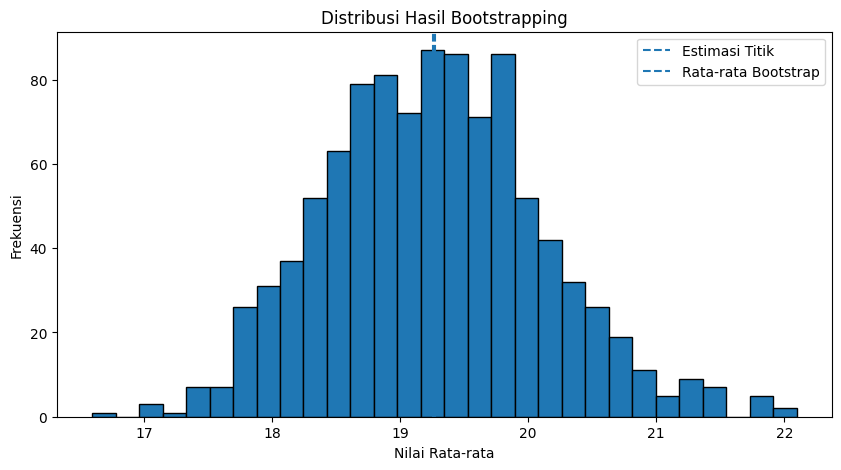

In [10]:

plt.figure(figsize=(10,5))

plt.hist(
    bootstrap_means,
    bins=30,
    edgecolor='black'
)

plt.axvline(
    mean_sample,
    linestyle='--',
    label='Estimasi Titik'
)

plt.axvline(
    mean_bootstrap,
    linestyle='--',
    label='Rata-rata Bootstrap'
)

plt.title('Distribusi Hasil Bootstrapping')
plt.xlabel('Nilai Rata-rata')
plt.ylabel('Frekuensi')
plt.legend()
plt.show()


In [11]:

print("========== HASIL AKHIR TUGAS ==========")

print("\n1. JUMLAH SAMPEL")
print("Jumlah data:", n)

print("\n2. ESTIMASI TITIK")
print("Rata-rata sampel:", mean_sample)

print("\n3. ESTIMASI INTERVAL Z")
print("Nilai Z:", z)
print("Batas bawah:", lower)
print("Batas atas:", upper)

print("\n4. JACKKNIFE")
print("Jumlah resampling:", len(jackknife_means))
print("Rata-rata Jackknife:", mean_jackknife)

print("\n5. BOOTSTRAPPING")
print("Jumlah iterasi:", len(bootstrap_means))
print("Rata-rata Bootstrap:", mean_bootstrap)

print("\n========== SELESAI ==========")


========== HASIL AKHIR TUGAS ==========

1. JUMLAH SAMPEL
Jumlah data: 100

2. ESTIMASI TITIK
Rata-rata sampel: 19.272100000000002

3. ESTIMASI INTERVAL Z
Nilai Z: 1.959963984540054
Batas bawah: 17.58311613699731
Batas atas: 20.961083863002692

4. JACKKNIFE
Jumlah resampling: 100
Rata-rata Jackknife: 19.272100000000002

5. BOOTSTRAPPING
Jumlah iterasi: 1000
Rata-rata Bootstrap: 19.2598626

========== SELESAI ==========
